In [ ]:
# 02 — Análisis Exploratorio de Datos (EDA)

## HMEQ Credit Risk

El objetivo de este notebook es explorar el comportamiento de las variables
financieras y crediticias del conjunto de datos HMEQ mediante técnicas de
estadística descriptiva y visualización.

Se estudiarán las distribuciones de las variables, sus medidas de tendencia
central y dispersión, la presencia de asimetrías y valores atípicos, así como
las primeras relaciones entre las características de los clientes y la
variable objetivo `BAD`.

Las decisiones relacionadas con imputación de valores ausentes o tratamiento
de valores atípicos se pospondrán hasta disponer de suficiente evidencia
estadística.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv(r"C:\Users\Sistemas\Desktop\BOOTCAMP DATA\Master Data Sciencie & AI\Proyecto banking\hmeq.csv")
df.shape


(5960, 13)

In [ ]:
## 1. Selección de variables numéricas

Se identifican las variables numéricas que serán objeto del análisis
exploratorio. La variable `BAD` se excluye de este grupo al tratarse de
la variable objetivo binaria.

In [5]:
numeric_cols = [
    "LOAN",
    "MORTDUE",
    "VALUE",
    "YOJ",
    "DEROG",
    "DELINQ",
    "CLAGE",
    "NINQ",
    "CLNO",
    "DEBTINC"
]

In [ ]:
BAD = 0 o 1

In [ ]:
## 2. Análisis univariante

### 2.1 Importe del préstamo (`LOAN`)

Se estudia inicialmente la distribución del importe de los préstamos mediante
medidas de tendencia central, dispersión y posición.

In [7]:
df["LOAN"].describe()

count     5960.000000
mean     18607.969799
std      11207.480417
min       1100.000000
25%      11100.000000
50%      16300.000000
75%      23300.000000
max      89900.000000
Name: LOAN, dtype: float64

In [8]:
loan_stats = {
    "media": df["LOAN"].mean(),
    "mediana": df["LOAN"].median(),
    "varianza": df["LOAN"].var(),
    "desviacion_estandar": df["LOAN"].std(),
    "asimetria": df["LOAN"].skew()
}

pd.Series(loan_stats)

media                  1.860797e+04
mediana                1.630000e+04
varianza               1.256076e+08
desviacion_estandar    1.120748e+04
asimetria              2.023781e+00
dtype: float64

In [ ]:
skew ≈ 0     → aproximadamente simétrica
skew > 0     → cola hacia la derecha
skew < 0     → cola hacia la izquierda

In [ ]:
## Histograma 

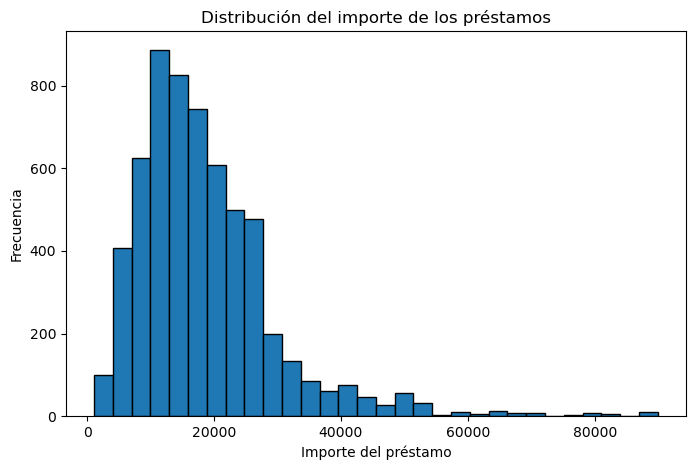

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["LOAN"], bins=30, edgecolor="black")

plt.title("Distribución del importe de los préstamos")
plt.xlabel("Importe del préstamo")
plt.ylabel("Frecuencia")

plt.show()

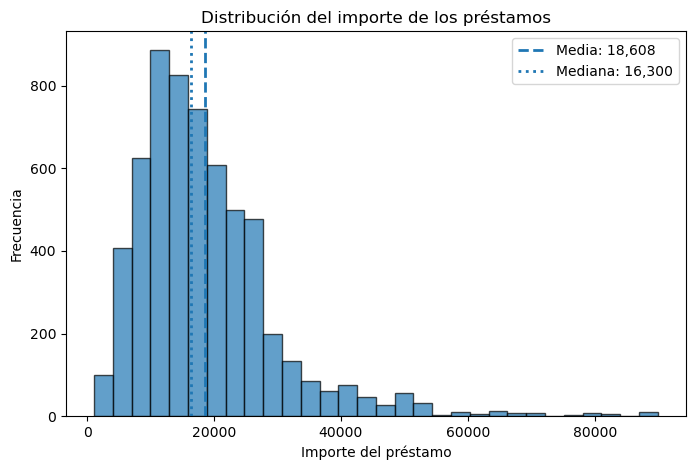

In [10]:
loan_mean = df["LOAN"].mean()
loan_median = df["LOAN"].median()

plt.figure(figsize=(8, 5))

plt.hist(df["LOAN"], bins=30, edgecolor="black", alpha=0.7)

plt.axvline(
    loan_mean,
    linestyle="--",
    linewidth=2,
    label=f"Media: {loan_mean:,.0f}"
)

plt.axvline(
    loan_median,
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {loan_median:,.0f}"
)

plt.title("Distribución del importe de los préstamos")
plt.xlabel("Importe del préstamo")
plt.ylabel("Frecuencia")
plt.legend()

plt.show()

In [ ]:
### Media>Mediana

y el histograma tiene una cola larga hacia valores altos, ambas cosas son coherentes con una asimetría positiva.

¿Por qué?

Porque unos pocos préstamos muy grandes arrastran la media hacia arriba, mientras que la mediana es mucho menos sensible.

In [ ]:
#### Identificación visual de posibles valores atípicos

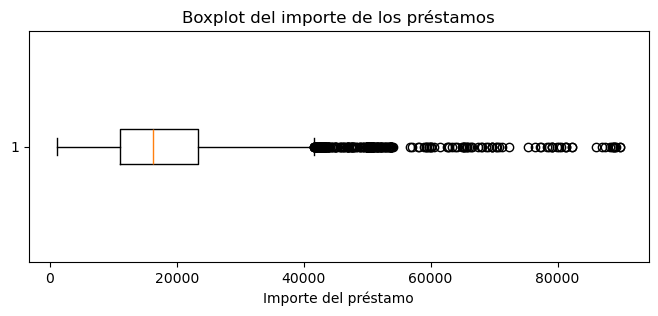

In [11]:
plt.figure(figsize=(8, 3))

plt.boxplot(
    df["LOAN"].dropna(),
    vert=False
)

plt.title("Boxplot del importe de los préstamos")
plt.xlabel("Importe del préstamo")

plt.show()

In [ ]:
#### Detección de valores potencialmente atípicos mediante IQR

In [12]:
q1 = df["LOAN"].quantile(0.25)
q3 = df["LOAN"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Q1: {q1:,.0f}")
print(f"Q3: {q3:,.0f}")
print(f"IQR: {iqr:,.0f}")
print(f"Límite inferior: {lower_bound:,.0f}")
print(f"Límite superior: {upper_bound:,.0f}")

Q1: 11,100
Q3: 23,300
IQR: 12,200
Límite inferior: -7,200
Límite superior: 41,600


In [13]:
loan_outliers = df[
    (df["LOAN"] < lower_bound) |
    (df["LOAN"] > upper_bound)
]

loan_outliers.shape[0]

256

In [14]:
loan_outlier_pct = len(loan_outliers) / len(df) * 100

print(f"Outliers de LOAN según IQR: {len(loan_outliers)}")
print(f"Porcentaje: {loan_outlier_pct:.2f}%")

Outliers de LOAN según IQR: 256
Porcentaje: 4.30%


In [ ]:
#### Interpretación de la distribución de LOAN

La distribución del importe de los préstamos presenta una asimetría positiva
marcada. La mayor parte de las observaciones se concentra en importes
relativamente bajos y medios, mientras que existe una cola prolongada hacia
importes elevados.

La media (18.608) es superior a la mediana (16.300), lo que resulta coherente
con la presencia de valores elevados que desplazan la media hacia la derecha.
Esta característica también queda reflejada en el coeficiente de asimetría,
que presenta un valor positivo de aproximadamente 2,02.

El 50 % central de los préstamos se encuentra entre 11.100 (Q1) y 23.300 (Q3).
El análisis mediante boxplot muestra además la presencia de observaciones
potencialmente atípicas en la parte superior de la distribución.

Estos valores no se eliminarán en esta fase, ya que un importe elevado no
implica necesariamente un error y podría contener información relevante para
el posterior análisis del riesgo de crédito.

In [ ]:
### 2.2 Resumen descriptivo de las variables numéricas

Tras analizar individualmente la variable `LOAN`, se amplía el análisis al
conjunto de variables numéricas con el objetivo de comparar sus principales
medidas de tendencia central, dispersión y forma.

Se analizarán la media, mediana, desviación estándar, cuartiles y asimetría,
prestando especial atención a aquellas variables que presenten distribuciones
muy asimétricas o posibles valores atípicos.

In [15]:
summary_stats = pd.DataFrame({
    "media": df[numeric_cols].mean(),
    "mediana": df[numeric_cols].median(),
    "std": df[numeric_cols].std(),
    "min": df[numeric_cols].min(),
    "q1": df[numeric_cols].quantile(0.25),
    "q3": df[numeric_cols].quantile(0.75),
    "max": df[numeric_cols].max(),
    "asimetria": df[numeric_cols].skew()
})

summary_stats.round(2)

,media,mediana,std,min,q1,q3,max,asimetria
LOAN,18607.97,16300.00,11207.48,1100.00,11100.00,23300.00,89900.00,2.02
MORTDUE,73760.82,65019.00,44457.61,2063.00,46276.00,91488.00,399550.00,1.81
VALUE,101776.05,89235.50,57385.78,8000.00,66075.50,119824.25,855909.00,3.05
YOJ,8.92,7.00,7.57,0.00,3.00,13.00,41.00,0.99
DEROG,0.25,0.00,0.85,0.00,0.00,0.00,10.00,5.32
DELINQ,0.45,0.00,1.13,0.00,0.00,0.00,15.00,4.02
CLAGE,179.77,173.47,85.81,0.00,115.12,231.56,1168.23,1.34
NINQ,1.19,1.00,1.73,0.00,0.00,2.00,17.00,2.62
CLNO,21.30,20.00,10.14,0.00,15.00,26.00,71.00,0.78
DEBTINC,33.78,34.82,8.60,0.52,29.14,39.00,203.31,2.85


In [ ]:
## 2.3 Distribuciones

Ahora vamos a visualizar todas las distribuciones numéricas.
En lugar de copiar diez veces el mismo código, hacemos un bucle:

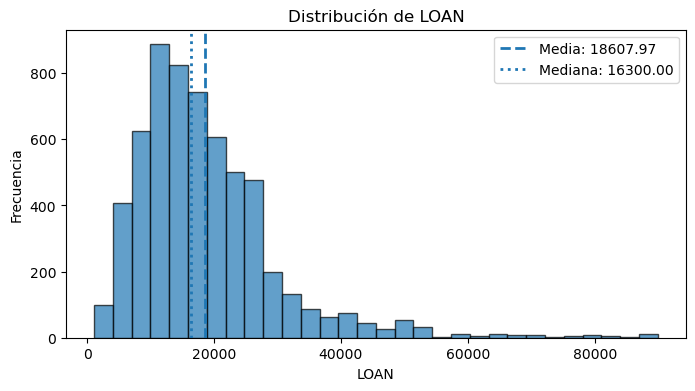

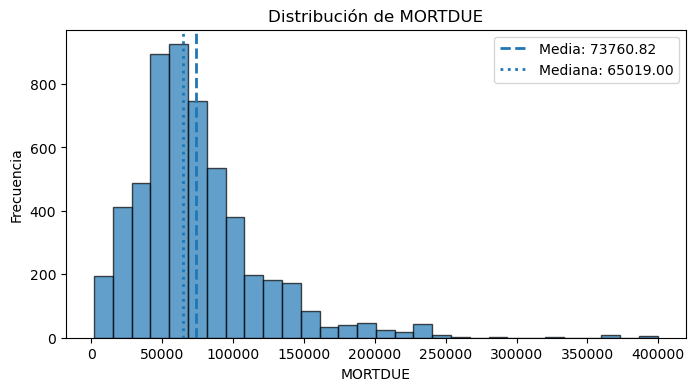

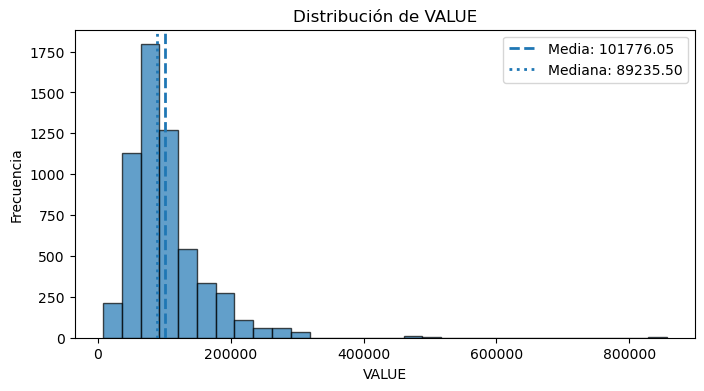

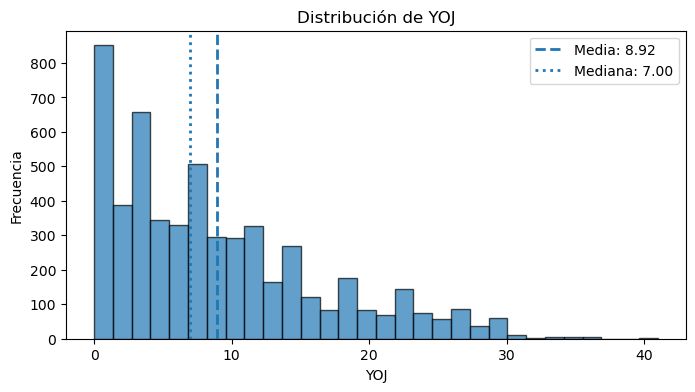

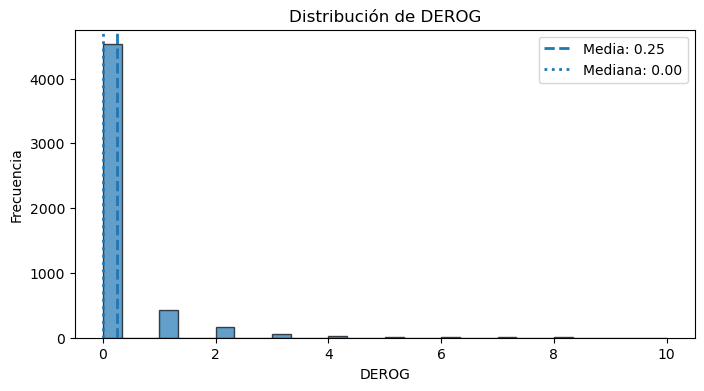

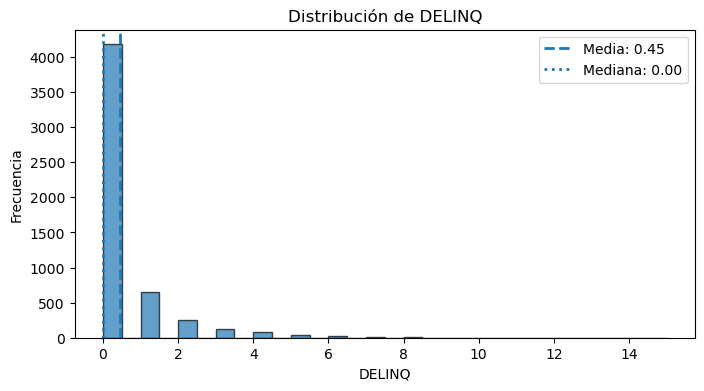

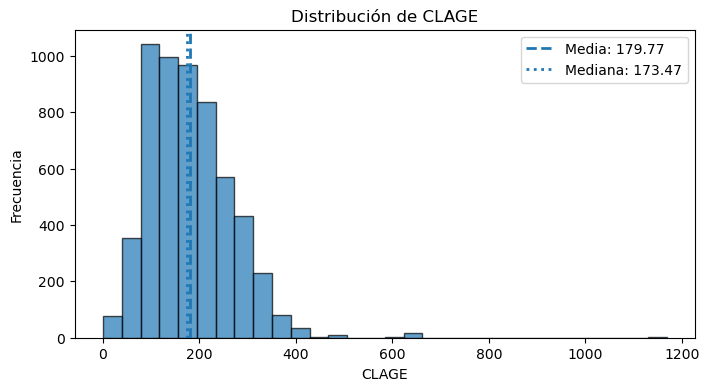

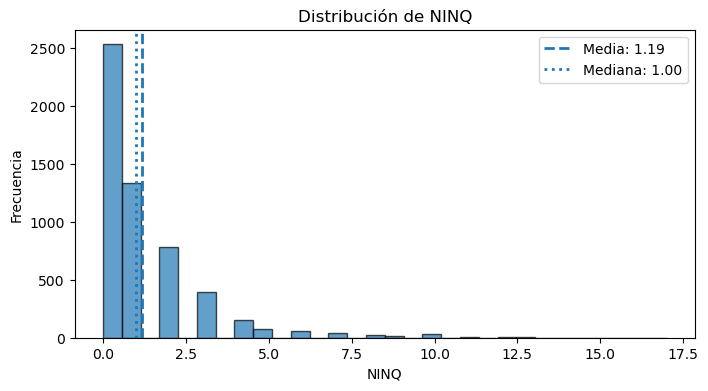

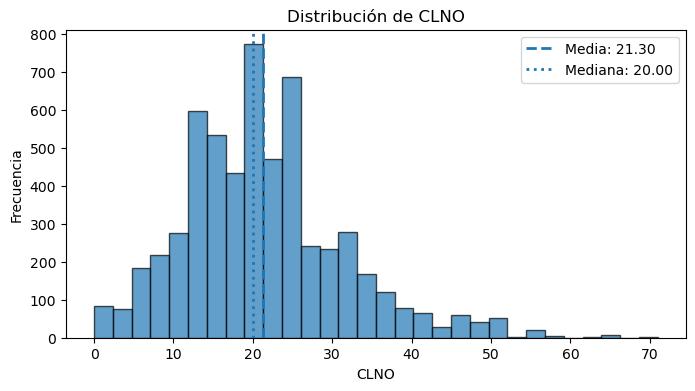

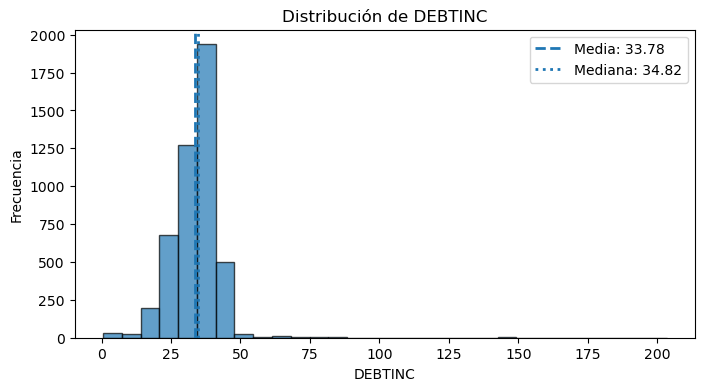

In [16]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    
    plt.hist(
        df[col].dropna(),
        bins=30,
        edgecolor="black",
        alpha=0.7
    )
    
    plt.axvline(
        df[col].mean(),
        linestyle="--",
        linewidth=2,
        label=f"Media: {df[col].mean():.2f}"
    )
    
    plt.axvline(
        df[col].median(),
        linestyle=":",
        linewidth=2,
        label=f"Mediana: {df[col].median():.2f}"
    )
    
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.legend()
    
    plt.show()

In [17]:
df[col]

0             NaN
1             NaN
2             NaN
3             NaN
4             NaN
          ...    
5955    36.112347
5956    35.859971
5957    35.556590
5958    34.340882
5959    34.571519
Name: DEBTINC, Length: 5960, dtype: float64

In [ ]:
### 2.4 Detección de valores potencialmente atípicos mediante IQR

Se utiliza el rango intercuartílico (IQR) como criterio descriptivo para
identificar observaciones alejadas del rango central de cada distribución.

La identificación mediante IQR no implica que las observaciones detectadas
sean erróneas ni que deban eliminarse automáticamente.

In [18]:
outlier_summary = []

for col in numeric_cols:
    
    series = df[col].dropna()
    
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = series[
        (series < lower_bound) |
        (series > upper_bound)
    ]
    
    outlier_summary.append({
        "variable": col,
        "limite_inferior": lower_bound,
        "limite_superior": upper_bound,
        "n_outliers": len(outliers),
        "pct_outliers": len(outliers) / len(series) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.round(2)

,variable,limite_inferior,limite_superior,n_outliers,pct_outliers
0,LOAN,-7200.00,41600.00,256,4.30
1,MORTDUE,-21542.00,159306.00,234,4.30
2,VALUE,-14547.62,200447.38,320,5.47
3,YOJ,-12.00,28.00,91,1.67
4,DEROG,0.00,0.00,725,13.80
5,DELINQ,0.00,0.00,1201,22.32
6,CLAGE,-59.55,406.23,47,0.83
7,NINQ,-3.00,5.00,177,3.25
8,CLNO,-1.50,42.50,219,3.82
9,DEBTINC,14.35,53.80,94,2.00


In [ ]:
#### Interpretación de los valores potencialmente atípicos

El criterio IQR identifica observaciones potencialmente atípicas en todas las
variables analizadas. Sin embargo, estos resultados deben interpretarse teniendo
en cuenta la naturaleza de cada variable.

Las variables financieras `LOAN`, `MORTDUE` y `VALUE` presentan distribuciones
asimétricas hacia la derecha, con una proporción relativamente reducida de
observaciones por encima del límite superior definido mediante IQR. Estos
valores pueden representar operaciones o propiedades de importe elevado y no
se consideran automáticamente errores.

En variables de conteo como `DEROG` y `DELINQ`, Q1, mediana y Q3 son iguales a
cero. Como consecuencia, el IQR es cero y cualquier valor superior a cero queda
clasificado automáticamente como atípico. En estos casos, el criterio IQR no
resulta adecuado como mecanismo automático de eliminación de observaciones.

También se observan valores extremos en variables como `VALUE`, `CLAGE` y
`DEBTINC`, que deberán estudiarse con mayor detalle antes de tomar cualquier
decisión de tratamiento.

Por tanto, en esta fase los valores identificados mediante IQR se consideran
observaciones potencialmente atípicas y no serán eliminados automáticamente.

In [ ]:
## 3. Análisis bivariante respecto a BAD

Una vez estudiadas las distribuciones individuales, se analiza la relación
entre las principales variables financieras y crediticias y la variable
objetivo `BAD`.

El objetivo de esta fase es identificar diferencias descriptivas entre los
clientes clasificados como `BAD = 0` y `BAD = 1`. Las diferencias observadas
en esta etapa no implican todavía significancia estadística ni causalidad.

In [19]:
df.groupby("BAD")["LOAN"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
BAD,,,,
0,4771,19028.11,16900.0,11115.76
1,1189,16922.12,14900.0,11418.46


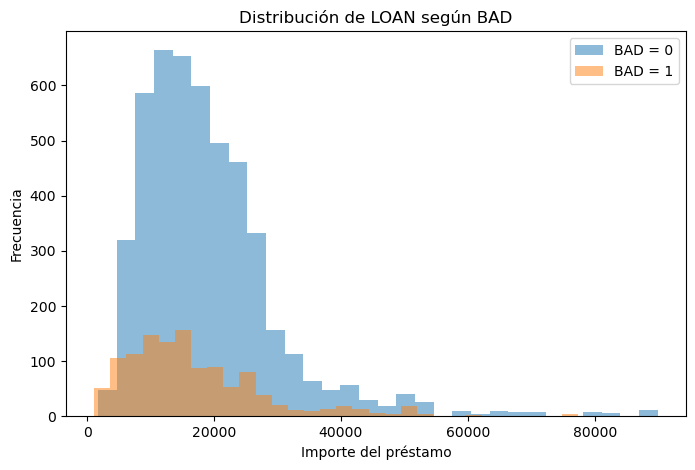

In [20]:
plt.figure(figsize=(8, 5))

plt.hist(
    df.loc[df["BAD"] == 0, "LOAN"],
    bins=30,
    alpha=0.5,
    label="BAD = 0"
)

plt.hist(
    df.loc[df["BAD"] == 1, "LOAN"],
    bins=30,
    alpha=0.5,
    label="BAD = 1"
)

plt.title("Distribución de LOAN según BAD")
plt.xlabel("Importe del préstamo")
plt.ylabel("Frecuencia")
plt.legend()

plt.show()

In [ ]:
## Normalizamos los histogramas 

In [21]:
density=True

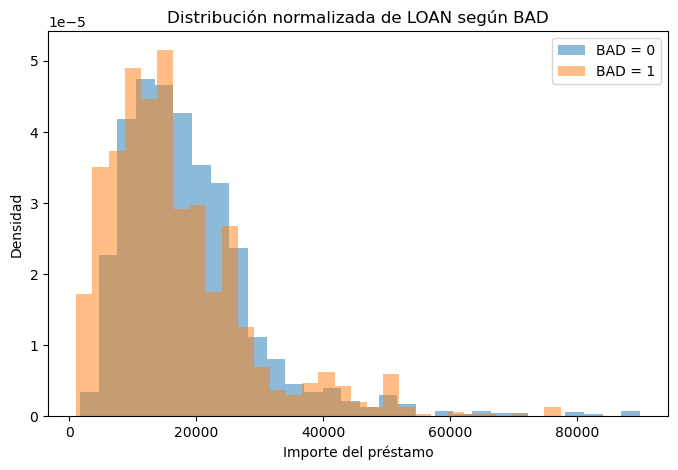

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(
    df.loc[df["BAD"] == 0, "LOAN"],
    bins=30,
    alpha=0.5,
    density=True,
    label="BAD = 0"
)

plt.hist(
    df.loc[df["BAD"] == 1, "LOAN"],
    bins=30,
    alpha=0.5,
    density=True,
    label="BAD = 1"
)

plt.title("Distribución normalizada de LOAN según BAD")
plt.xlabel("Importe del préstamo")
plt.ylabel("Densidad")
plt.legend()

plt.show()

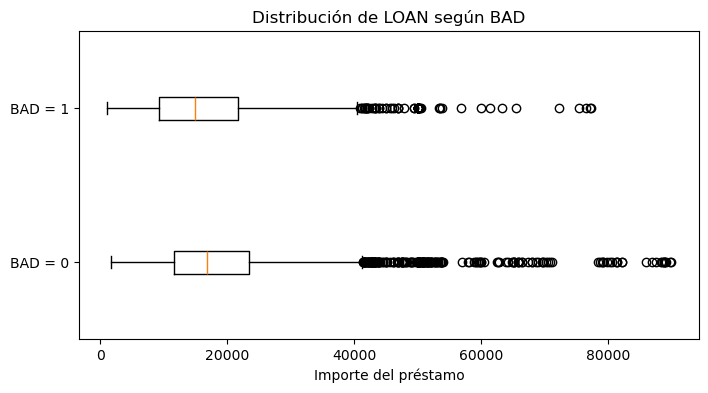

In [23]:
loan_bad0 = df.loc[df["BAD"] == 0, "LOAN"]
loan_bad1 = df.loc[df["BAD"] == 1, "LOAN"]

plt.figure(figsize=(8, 4))

plt.boxplot(
    [loan_bad0, loan_bad1],
    tick_labels=["BAD = 0", "BAD = 1"],
    vert=False
)

plt.title("Distribución de LOAN según BAD")
plt.xlabel("Importe del préstamo")

plt.show()

In [ ]:
#### Relación descriptiva entre LOAN y BAD

En la muestra analizada se observan diferencias en la distribución del importe
del préstamo entre ambas clases de la variable objetivo.

Los clientes con `BAD = 0` presentan un importe medio de aproximadamente 19.028
y una mediana de 16.900, mientras que los clientes con `BAD = 1` presentan una
media de aproximadamente 16.922 y una mediana de 14.900.

Por tanto, descriptivamente, el grupo `BAD = 1` presenta importes de préstamo
algo menores. No obstante, esta diferencia observada no permite concluir por sí
sola que exista una relación estadísticamente significativa ni una relación
causal entre el importe del préstamo y el riesgo de crédito.

La significancia y magnitud de esta asociación se evaluarán posteriormente
mediante técnicas de inferencia estadística.

In [ ]:
### 3.2 Comparación de variables numéricas según BAD

Se comparan las principales medidas descriptivas de las variables numéricas
entre los grupos `BAD = 0` y `BAD = 1`.

El objetivo es identificar variables que presenten diferencias relevantes entre
ambos grupos y seleccionar aquellas que merezcan un análisis posterior más
detallado.

In [25]:
comparison_bad = df.groupby("BAD")[numeric_cols].agg(["mean", "median"])

comparison_bad.round(2)

LOAN            MORTDUE               VALUE            YOJ         \
         mean   median      mean   median       mean   median  mean median   
BAD                                                                          
0    19028.11  16900.0  74829.25  66839.0  102595.92  90659.0  9.15    7.0   
1    16922.12  14900.0  69460.45  60279.0   98172.85  82000.0  8.03    6.0   

    DEROG        DELINQ          CLAGE          NINQ          CLNO         \
     mean median   mean median    mean  median  mean median   mean median   
BAD                                                                         
0    0.13    0.0   0.25    0.0  187.00  180.42  1.03    1.0  21.32   20.0   
1    0.71    0.0   1.23    0.0  150.19  132.87  1.78    1.0  21.21   20.0   

    DEBTINC         
       mean median  
BAD                 
0     33.25  34.54  
1     39.39  38.08

In [26]:
comparison = pd.DataFrame({
    "media_BAD_0": df.loc[df["BAD"] == 0, numeric_cols].mean(),
    "media_BAD_1": df.loc[df["BAD"] == 1, numeric_cols].mean(),
    "mediana_BAD_0": df.loc[df["BAD"] == 0, numeric_cols].median(),
    "mediana_BAD_1": df.loc[df["BAD"] == 1, numeric_cols].median()
})

comparison.round(2)

,media_BAD_0,media_BAD_1,mediana_BAD_0,mediana_BAD_1
LOAN,19028.11,16922.12,16900.00,14900.00
MORTDUE,74829.25,69460.45,66839.00,60279.00
VALUE,102595.92,98172.85,90659.00,82000.00
YOJ,9.15,8.03,7.00,6.00
DEROG,0.13,0.71,0.00,0.00
DELINQ,0.25,1.23,0.00,0.00
CLAGE,187.00,150.19,180.42,132.87
NINQ,1.03,1.78,1.00,1.00
CLNO,21.32,21.21,20.00,20.00
DEBTINC,33.25,39.39,34.54,38.08


In [27]:
comparison["dif_media_pct"] = (
    (comparison["media_BAD_1"] - comparison["media_BAD_0"])
    / comparison["media_BAD_0"]
    * 100
)

comparison["dif_mediana_pct"] = (
    (comparison["mediana_BAD_1"] - comparison["mediana_BAD_0"])
    / comparison["mediana_BAD_0"]
    * 100
)

comparison.round(2)

,media_BAD_0,media_BAD_1,mediana_BAD_0,mediana_BAD_1,dif_media_pct,dif_mediana_pct
LOAN,19028.11,16922.12,16900.00,14900.00,-11.07,-11.83
MORTDUE,74829.25,69460.45,66839.00,60279.00,-7.17,-9.81
VALUE,102595.92,98172.85,90659.00,82000.00,-4.31,-9.55
YOJ,9.15,8.03,7.00,6.00,-12.31,-14.29
DEROG,0.13,0.71,0.00,0.00,427.36,NaN
DELINQ,0.25,1.23,0.00,0.00,401.44,NaN
CLAGE,187.00,150.19,180.42,132.87,-19.69,-26.36
NINQ,1.03,1.78,1.00,1.00,72.62,0.00
CLNO,21.32,21.21,20.00,20.00,-0.50,0.00
DEBTINC,33.25,39.39,34.54,38.08,18.45,10.24


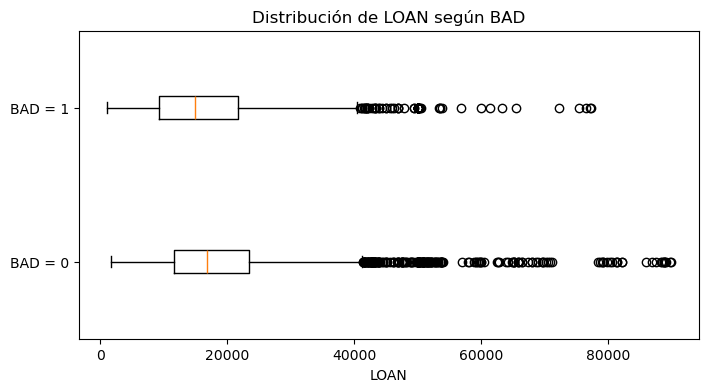

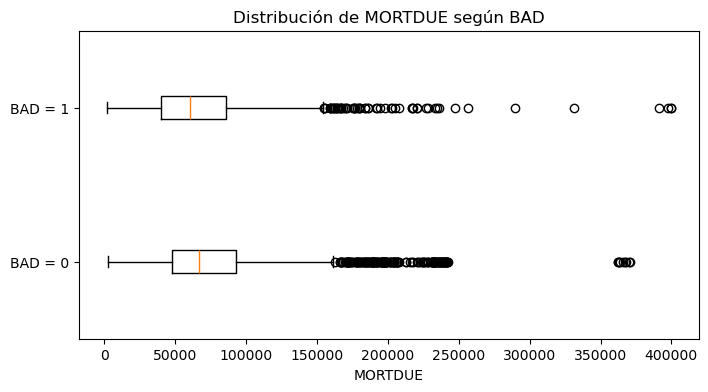

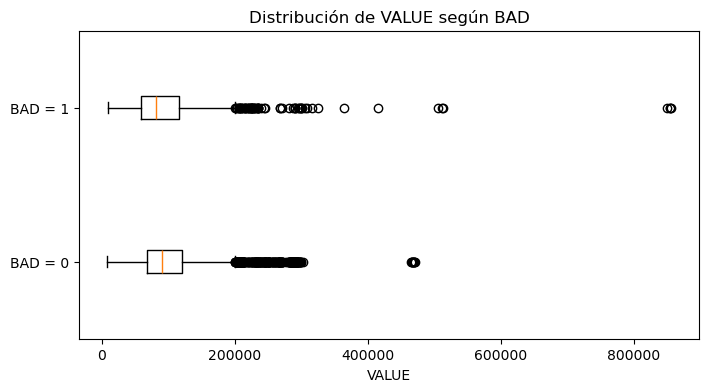

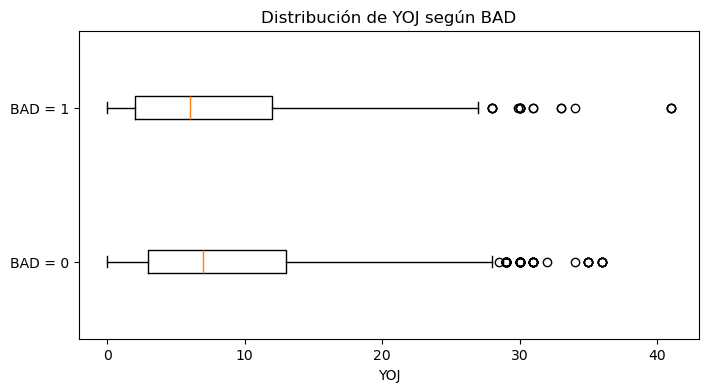

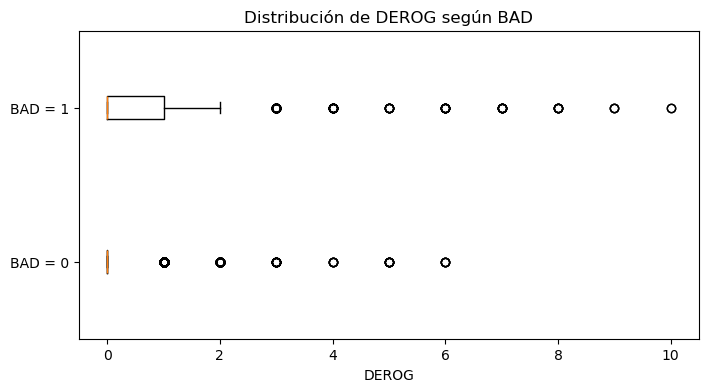

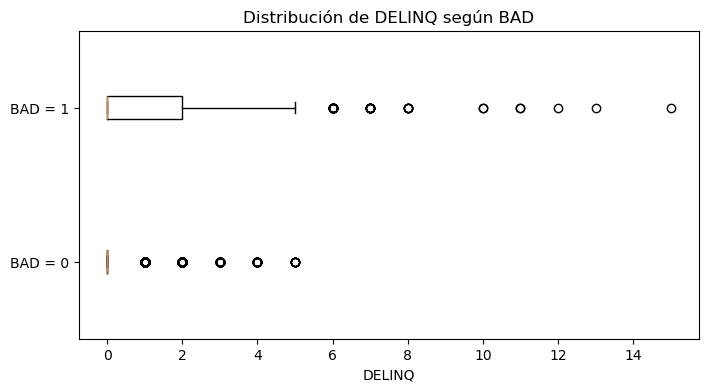

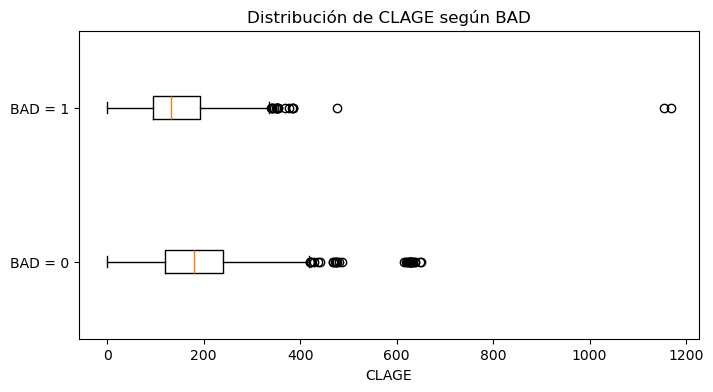

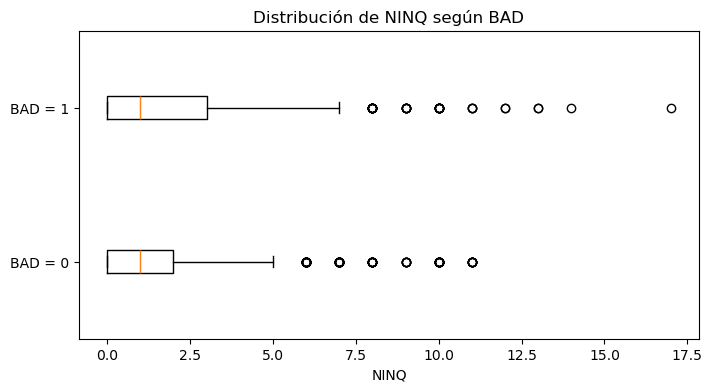

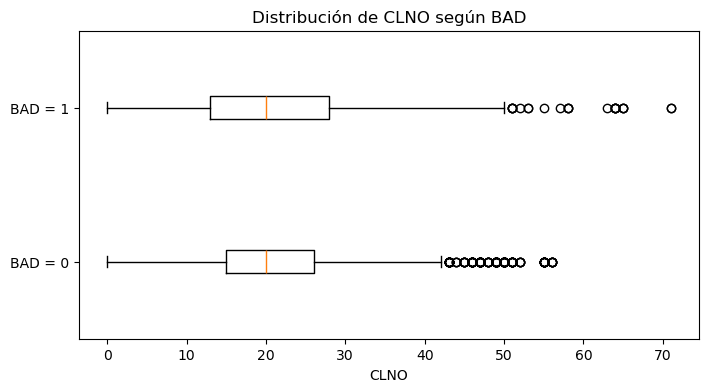

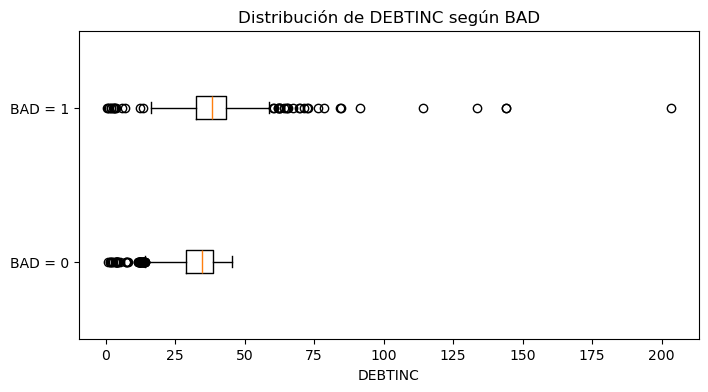

In [28]:
for col in numeric_cols:
    
    data_bad0 = df.loc[df["BAD"] == 0, col].dropna()
    data_bad1 = df.loc[df["BAD"] == 1, col].dropna()
    
    plt.figure(figsize=(8, 4))
    
    plt.boxplot(
        [data_bad0, data_bad1],
        tick_labels=["BAD = 0", "BAD = 1"],
        vert=False
    )
    
    plt.title(f"Distribución de {col} según BAD")
    plt.xlabel(col)
    
    plt.show()

In [29]:
comparison.round(2)

,media_BAD_0,media_BAD_1,mediana_BAD_0,mediana_BAD_1,dif_media_pct,dif_mediana_pct
LOAN,19028.11,16922.12,16900.00,14900.00,-11.07,-11.83
MORTDUE,74829.25,69460.45,66839.00,60279.00,-7.17,-9.81
VALUE,102595.92,98172.85,90659.00,82000.00,-4.31,-9.55
YOJ,9.15,8.03,7.00,6.00,-12.31,-14.29
DEROG,0.13,0.71,0.00,0.00,427.36,NaN
DELINQ,0.25,1.23,0.00,0.00,401.44,NaN
CLAGE,187.00,150.19,180.42,132.87,-19.69,-26.36
NINQ,1.03,1.78,1.00,1.00,72.62,0.00
CLNO,21.32,21.21,20.00,20.00,-0.50,0.00
DEBTINC,33.25,39.39,34.54,38.08,18.45,10.24


In [ ]:
#### Primeras observaciones de la comparación según BAD

La comparación descriptiva entre los grupos `BAD = 0` y `BAD = 1` muestra
diferencias en varias de las características financieras y crediticias.

- `DELINQ` presenta una media de 0,25 para `BAD = 0` y de 1,23 para
  `BAD = 1`, mientras que la mediana permanece en 0 en ambos grupos.
  Esto indica una fuerte concentración de observaciones en cero, aunque el
  grupo `BAD = 1` presenta valores de morosidad más elevados en parte de
  su distribución.

- `DEROG` muestra un patrón similar: la media es considerablemente superior
  en el grupo `BAD = 1`, mientras que la mediana es 0 en ambos grupos.

- `CLAGE` presenta valores inferiores en el grupo `BAD = 1`. Su mediana
  pasa de 180,42 meses en `BAD = 0` a 132,87 meses en `BAD = 1`.
  Descriptivamente, los clientes clasificados como `BAD = 1` presentan
  una menor antigüedad de su historial crediticio.

- `NINQ` presenta una media superior en `BAD = 1` (1,78) respecto a
  `BAD = 0` (1,03), aunque la mediana es 1 en ambos grupos.

- `DEBTINC` presenta valores superiores en el grupo `BAD = 1`, tanto en
  media (39,39 frente a 33,25) como en mediana (38,08 frente a 34,54).
  Esto sugiere una posible asociación entre un mayor nivel de endeudamiento
  relativo y la variable objetivo.

- `LOAN`, `MORTDUE`, `VALUE` y `YOJ` presentan valores medios y medianos
  algo inferiores en el grupo `BAD = 1`.

Estas diferencias son descriptivas y permiten generar hipótesis sobre las
variables potencialmente relacionadas con el riesgo de crédito. No implican
causalidad ni permiten afirmar todavía que las diferencias sean
estadísticamente significativas.

In [ ]:
### 3.3 Visualización de variables crediticias seleccionadas

A partir del análisis descriptivo anterior, se seleccionan algunas variables
que presentan diferencias entre los grupos `BAD = 0` y `BAD = 1` para
visualizar con mayor claridad su comportamiento.

In [30]:
delinq_bad = (
    df.groupby("DELINQ")["BAD"]
      .agg(["count", "mean"])
      .reset_index()
)

delinq_bad["bad_rate"] = delinq_bad["mean"] * 100

delinq_bad.round(2)

,DELINQ,count,mean,bad_rate
0,0.0,4179,0.14,13.95
1,1.0,654,0.34,33.94
2,2.0,250,0.45,44.80
3,3.0,129,0.55,55.04
4,4.0,78,0.59,58.97
5,5.0,38,0.82,81.58
6,6.0,27,1.00,100.00
7,7.0,13,1.00,100.00
8,8.0,5,1.00,100.00
9,10.0,2,1.00,100.00


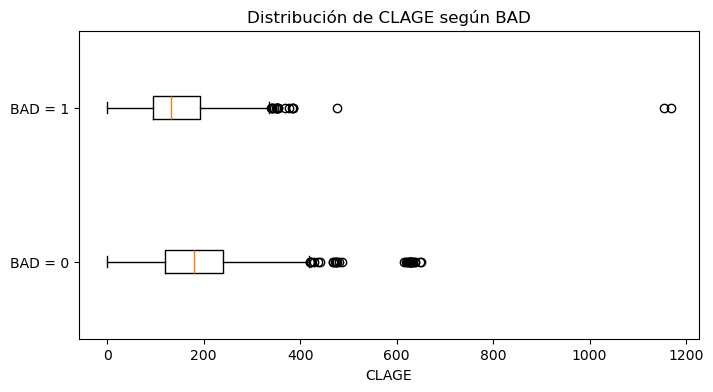

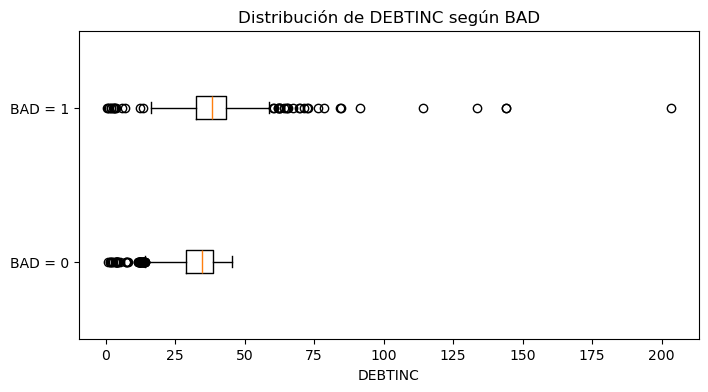

In [31]:
for col in ["CLAGE", "DEBTINC"]:
    
    bad0 = df.loc[df["BAD"] == 0, col].dropna()
    bad1 = df.loc[df["BAD"] == 1, col].dropna()
    
    plt.figure(figsize=(8, 4))
    
    plt.boxplot(
        [bad0, bad1],
        tick_labels=["BAD = 0", "BAD = 1"],
        vert=False
    )
    
    plt.title(f"Distribución de {col} según BAD")
    plt.xlabel(col)
    
    plt.show()

In [ ]:
## 4. Análisis de variables categóricas

Se analiza la tasa de `BAD` para las distintas categorías de `REASON` y `JOB`
con el objetivo de identificar posibles diferencias descriptivas en el riesgo
de crédito entre grupos.

In [32]:
for col in ["REASON", "JOB"]:
    
    result = (
        df.groupby(col)["BAD"]
          .agg(["count", "mean"])
          .sort_values("mean", ascending=False)
    )
    
    result["bad_rate"] = result["mean"] * 100
    
    print(f"\n--- {col} ---")
    print(result.round(2))


--- REASON ---
         count  mean  bad_rate
REASON                        
HomeImp   1780  0.22     22.25
DebtCon   3928  0.19     18.97

--- JOB ---
         count  mean  bad_rate
JOB                           
Sales      109  0.35     34.86
Self       193  0.30     30.05
Mgr        767  0.23     23.34
Other     2388  0.23     23.20
ProfExe   1276  0.17     16.61
Office     948  0.13     13.19


In [ ]:
## 5. Conclusiones del análisis exploratorio

El análisis exploratorio muestra que existen diferencias descriptivas entre
los clientes clasificados como `BAD = 0` y `BAD = 1`.

Entre los principales resultados destacan:

- `DELINQ` presenta una relación descriptiva clara con la variable objetivo.
  La tasa observada de `BAD` aumenta desde aproximadamente un 14 % para
  clientes sin morosidades previas hasta valores superiores al 50 % a partir
  de tres morosidades. Las categorías con valores muy elevados de `DELINQ`
  contienen pocas observaciones, por lo que sus tasas deben interpretarse
  con cautela.

- `CLAGE` presenta valores inferiores entre los clientes `BAD = 1`,
  sugiriendo una posible asociación entre una menor antigüedad del historial
  crediticio y el riesgo de crédito.

- `DEBTINC` presenta valores superiores en el grupo `BAD = 1`, lo que sugiere
  una posible asociación entre un mayor endeudamiento relativo y el riesgo
  de crédito.

- Variables como `DEROG` y `NINQ` también muestran diferencias entre ambos
  grupos y podrían aportar información relevante en análisis posteriores.

- Las variables categóricas muestran diferencias en las tasas observadas de
  `BAD`. En `JOB`, por ejemplo, las categorías Sales y Self presentan tasas
  superiores a Office, aunque el diferente tamaño de las categorías obliga
  a interpretar estas comparaciones con cautela.

- Se han identificado distribuciones asimétricas y valores extremos en varias
  variables. Estos valores no se eliminarán automáticamente, ya que pueden
  representar observaciones financieras legítimas y potencialmente
  informativas.

Los resultados obtenidos son descriptivos. Las diferencias observadas no
implican causalidad ni garantizan significancia estadística. El siguiente
paso será aplicar técnicas de inferencia estadística para evaluar qué
relaciones presentan evidencia estadística suficiente.